# Predicting Agreement with an Antifeminist Statement

## Research question

Can sociodemographic characteristics predict agreement with the statement:
“Feminism threatens men's place and role in society”?

## Business context

CIDFF Rhône–Arc Alpin is exploring themes to develop its prevention
and awareness activities.

This analysis examines associations between sociodemographic
characteristics and one declared attitude in the national HCE survey.
It may inform discussion about prevention topics and audiences.

## Target

- 1: Strongly agree or somewhat agree.
- 0: Somewhat disagree or strongly disagree.

Non-response and “Don't know” answers are excluded from this binary target.

## Scope and limitations

One answer does not identify someone as masculinist or dangerous.
Predictive associations do not establish causality or demonstrate
the effectiveness of an awareness activity.

Results concern respondents with an expressed opinion in this national
survey. They do not directly describe CIDFF users or local populations.

## Step 0 — Imports and Data Loading

In [1]:
import pandas as pd

# Load the original survey so this notebook runs independently
hce = pd.read_csv(
    "base-de-donnees-toluna-harris-barometre-sexisme-vague-5-2025-dgcs-hce-.csv",
    sep=";",
    dtype="string"
)

print("Survey shape:", hce.shape)

Survey shape: (3061, 264)


## Step 1 — EDA and Data Preparation

Select the target and sociodemographic predictors.
Check response labels, missing values and survey weights before modeling.

In [2]:
# Select predictors and the target question
column_codes = {
    "SEXE": "sex",
    "AGE_1": "age",
    "DIPLOME": "education",
    "ACTIVITE_REP": "employment_status",
    "REC_TailleAgglo5": "urban_area_size",
    "Q4_19": "target_response"
}

selected_columns = {}

for code, short_name in column_codes.items():
    original_name = next(
        column for column in hce.columns
        if column.startswith(code + " :")
    )
    selected_columns[original_name] = short_name

ml_data = hce[list(selected_columns)].rename(
    columns=selected_columns
).copy()

# Keep identifiers and survey weights outside the predictors
ml_data["respondent_id"] = hce["responseid"]
ml_data["survey_weight"] = pd.to_numeric(
    hce["POIDS"].str.replace(",", ".", regex=False),
    errors="raise"
)

# Define the binary target
target_mapping = {
    "Tout à fait d’accord": 1,
    "Plutôt d’accord": 1,
    "Plutôt pas d’accord": 0,
    "Pas du tout d’accord": 0
}

ml_data["target"] = ml_data["target_response"].map(target_mapping)

print("Excluded responses:", ml_data["target"].isna().sum())

# Keep expressed opinions and convert age to a number
ml_data = ml_data.dropna(subset=["target"]).copy()
ml_data["target"] = ml_data["target"].astype(int)
ml_data["age"] = pd.to_numeric(ml_data["age"], errors="raise")

print("Usable respondents:", len(ml_data))
print("\nTarget counts:")
print(ml_data["target"].value_counts().sort_index())

Excluded responses: 282
Usable respondents: 2779

Target counts:
target
0    1806
1     973
Name: count, dtype: int64


In [3]:
# Check predictor quality before splitting the data
features = [
    "sex", "age", "education",
    "employment_status", "urban_area_size"
]

print("Missing predictor values:")
print(ml_data[features].isna().sum())

print("\nMissing respondent IDs:",
      ml_data["respondent_id"].isna().sum())
print("Duplicate respondent IDs:",
      ml_data["respondent_id"].duplicated().sum())

print("\nMissing survey weights:",
      ml_data["survey_weight"].isna().sum())
print("Zero or negative survey weights:",
      ml_data["survey_weight"].le(0).sum())

print("\nAge range:",
      ml_data["age"].min(), "to", ml_data["age"].max())

Missing predictor values:
sex                  0
age                  0
education            0
employment_status    0
urban_area_size      0
dtype: int64

Missing respondent IDs: 0
Duplicate respondent IDs: 0

Missing survey weights: 0
Zero or negative survey weights: 0

Age range: 15 to 90


### Data preparation results

The binary target includes 2,779 respondents:
- 973 agree with the statement.
- 1,806 disagree with the statement.

The 282 non-response or “Don't know” answers were excluded.

The five selected predictors have no missing values.
Respondent IDs are complete and unique.
Survey weights are complete and positive.
Respondents are aged 15 to 90.

The respondent ID, survey weight and original target response
will not be included in the predictor matrix.

## Step 2 — Train / Test Split

Reserve 20% of respondents for final testing.
Keep similar class proportions in both sets.
Model selection and tuning will use the training set only.

In [4]:
from sklearn.model_selection import train_test_split

SEED = 42

# Define predictors, target and survey weights separately
X = ml_data[features].copy()
y = ml_data["target"]
survey_weights = ml_data["survey_weight"].astype(float)

# Split all three together to keep respondents aligned
X_train, X_test, y_train, y_test, weights_train, weights_test = (
    train_test_split(
        X,
        y,
        survey_weights,
        test_size=0.20,
        random_state=SEED,
        stratify=y
    )
)

print("Training respondents:", len(X_train))
print("Test respondents:", len(X_test))
print(
    "Shared respondents:",
    len(set(X_train.index).intersection(X_test.index))
)

Training respondents: 2223
Test respondents: 556
Shared respondents: 0


## Step 3 — Feature Engineering

Standardize age and encode categorical predictors with one-hot encoding.
Learn transformations from the training set only.
Apply the same transformations to the test set.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["age"]

categorical_features = [
    "sex",
    "education",
    "employment_status",
    "urban_area_size"
]

# Define the preparation for each type of variable
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Learn transformations from training data only
X_train_prepared = preprocessor.fit_transform(X_train)

# Apply the same transformations to the test data
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (2223, 27)
Prepared test shape: (556, 27)


## Step 4 — Baseline and Model Training

### Evaluation strategy

A baseline that always predicts the majority class will provide
a minimum reference.

Models will be compared using stratified three-fold cross-validation
on the training set. Preprocessing will be fitted separately within
each training fold.

The main comparison metric will be survey-weighted balanced accuracy.
It gives equal importance to recall for agreement and disagreement.

We will also examine precision, recall, F1-score and ROC AUC.
The final test set will remain unused during model selection and tuning.

Survey weights account for the survey weighting scheme.
They are different from class weights used to address class imbalance.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Keep the same validation folds for all models
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(cv.split(X_train, y_train))
baseline_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    baseline = DummyClassifier(strategy="most_frequent")

    baseline.fit(
        X_train.iloc[train_index],
        y_train.iloc[train_index],
        sample_weight=weights_train.iloc[train_index]
    )

    predictions = baseline.predict(X_train.iloc[valid_index])

    baseline_results.append({
        "fold": fold,
        "accuracy": accuracy_score(
            y_train.iloc[valid_index],
            predictions,
            sample_weight=weights_train.iloc[valid_index]
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_train.iloc[valid_index],
            predictions,
            sample_weight=weights_train.iloc[valid_index]
        )
    })

baseline_scores = pd.DataFrame(baseline_results)

display(baseline_scores.round(3))
print(
    "Mean balanced accuracy:",
    round(baseline_scores["balanced_accuracy"].mean(), 3)
)

,fold,accuracy,balanced_accuracy
0,1,0.646,0.5
1,2,0.647,0.5
2,3,0.650,0.5


Mean balanced accuracy: 0.5


In [7]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier

# Keep preprocessing and model training together
logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", SGDClassifier(
        loss="log_loss",
        max_iter=5000,
        tol=0.0001,
        random_state=SEED
    ))
])

logistic_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    model = clone(logistic_pipeline)

    # Fit preprocessing and model on this training fold only
    model.fit(
        X_train.iloc[train_index],
        y_train.iloc[train_index],
        model__sample_weight=weights_train.iloc[train_index]
    )

    train_predictions = model.predict(X_train.iloc[train_index])
    valid_predictions = model.predict(X_train.iloc[valid_index])

    logistic_results.append({
        "fold": fold,
        "train_balanced_accuracy": balanced_accuracy_score(
            y_train.iloc[train_index],
            train_predictions,
            sample_weight=weights_train.iloc[train_index]
        ),
        "valid_balanced_accuracy": balanced_accuracy_score(
            y_train.iloc[valid_index],
            valid_predictions,
            sample_weight=weights_train.iloc[valid_index]
        )
    })

logistic_scores = pd.DataFrame(logistic_results)

display(logistic_scores.round(3))
print("\nMean scores:")
print(logistic_scores.drop(columns="fold").mean().round(3))

,fold,train_balanced_accuracy,valid_balanced_accuracy
0,1,0.508,0.499
1,2,0.558,0.574
2,3,0.579,0.535



Mean scores:
train_balanced_accuracy    0.548
valid_balanced_accuracy    0.536
dtype: float64


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Limit tree complexity for the first comparison
forest_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=1
    ))
])

forest_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    model = clone(forest_pipeline)

    model.fit(
        X_train.iloc[train_index],
        y_train.iloc[train_index],
        model__sample_weight=weights_train.iloc[train_index]
    )

    train_predictions = model.predict(X_train.iloc[train_index])
    valid_predictions = model.predict(X_train.iloc[valid_index])

    forest_results.append({
        "fold": fold,
        "train_balanced_accuracy": balanced_accuracy_score(
            y_train.iloc[train_index],
            train_predictions,
            sample_weight=weights_train.iloc[train_index]
        ),
        "valid_balanced_accuracy": balanced_accuracy_score(
            y_train.iloc[valid_index],
            valid_predictions,
            sample_weight=weights_train.iloc[valid_index]
        )
    })

forest_scores = pd.DataFrame(forest_results)

display(forest_scores.round(3))
print("\nMean scores:")
print(forest_scores.drop(columns="fold").mean().round(3))

,fold,train_balanced_accuracy,valid_balanced_accuracy
0,1,0.506,0.504
1,2,0.500,0.500
2,3,0.500,0.502



Mean scores:
train_balanced_accuracy    0.502
valid_balanced_accuracy    0.502
dtype: float64


In [9]:
# Inspect predictions from the last validation fold
prediction_counts = pd.DataFrame({
    "actual": y_train.iloc[valid_index].to_numpy(),
    "predicted": valid_predictions
})

print("Actual class counts:")
print(prediction_counts["actual"].value_counts().sort_index())

print("\nPredicted class counts:")
print(prediction_counts["predicted"].value_counts().sort_index())

# Check whether probabilities distinguish the two classes
from sklearn.metrics import roc_auc_score

valid_probabilities = model.predict_proba(
    X_train.iloc[valid_index]
)[:, 1]

print(
    "\nValidation ROC AUC:",
    round(
        roc_auc_score(
            y_train.iloc[valid_index],
            valid_probabilities,
            sample_weight=weights_train.iloc[valid_index]
        ),
        3
    )
)

Actual class counts:
actual
0    481
1    260
Name: count, dtype: int64

Predicted class counts:
predicted
0    740
1      1
Name: count, dtype: int64

Validation ROC AUC: 0.579


In [10]:
# Compare tree complexity using the same validation folds
forest_tuning_results = []

for depth in [5, 10, None]:
    for leaf_size in [1, 5]:
        train_scores = []
        valid_scores = []

        for train_index, valid_index in cv_splits:
            candidate = clone(forest_pipeline)

            candidate.set_params(
                model__max_depth=depth,
                model__min_samples_leaf=leaf_size
            )

            candidate.fit(
                X_train.iloc[train_index],
                y_train.iloc[train_index],
                model__sample_weight=weights_train.iloc[train_index]
            )

            train_predictions = candidate.predict(
                X_train.iloc[train_index]
            )
            valid_predictions = candidate.predict(
                X_train.iloc[valid_index]
            )

            train_scores.append(
                balanced_accuracy_score(
                    y_train.iloc[train_index],
                    train_predictions,
                    sample_weight=weights_train.iloc[train_index]
                )
            )

            valid_scores.append(
                balanced_accuracy_score(
                    y_train.iloc[valid_index],
                    valid_predictions,
                    sample_weight=weights_train.iloc[valid_index]
                )
            )

        forest_tuning_results.append({
            "max_depth": str(depth),
            "min_samples_leaf": leaf_size,
            "train_balanced_accuracy": sum(train_scores) / len(train_scores),
            "valid_balanced_accuracy": sum(valid_scores) / len(valid_scores)
        })

forest_tuning = pd.DataFrame(forest_tuning_results)

display(
    forest_tuning.sort_values(
        "valid_balanced_accuracy", ascending=False
    ).round(3)
)

,max_depth,min_samples_leaf,train_balanced_accuracy,valid_balanced_accuracy
4,None,1,0.944,0.525
2,10,1,0.692,0.509
5,None,5,0.584,0.508
3,10,5,0.547,0.506
1,5,5,0.502,0.502
0,5,1,0.510,0.500


In [11]:
# Compare regularization and class weighting
logistic_tuning_results = []

for alpha in [0.0001, 0.001, 0.01]:
    for class_weight in [None, "balanced"]:
        train_scores = []
        valid_scores = []

        for train_index, valid_index in cv_splits:
            candidate = clone(logistic_pipeline)

            candidate.set_params(
                model__alpha=alpha,
                model__class_weight=class_weight
            )

            candidate.fit(
                X_train.iloc[train_index],
                y_train.iloc[train_index],
                model__sample_weight=weights_train.iloc[train_index]
            )

            train_predictions = candidate.predict(
                X_train.iloc[train_index]
            )
            valid_predictions = candidate.predict(
                X_train.iloc[valid_index]
            )

            train_scores.append(
                balanced_accuracy_score(
                    y_train.iloc[train_index],
                    train_predictions,
                    sample_weight=weights_train.iloc[train_index]
                )
            )

            valid_scores.append(
                balanced_accuracy_score(
                    y_train.iloc[valid_index],
                    valid_predictions,
                    sample_weight=weights_train.iloc[valid_index]
                )
            )

        logistic_tuning_results.append({
            "alpha": alpha,
            "class_weight": str(class_weight),
            "train_balanced_accuracy": sum(train_scores) / len(train_scores),
            "valid_balanced_accuracy": sum(valid_scores) / len(valid_scores),
            "valid_std": pd.Series(valid_scores).std(ddof=0)
        })

logistic_tuning = pd.DataFrame(logistic_tuning_results)

display(
    logistic_tuning.sort_values(
        "valid_balanced_accuracy", ascending=False
    ).round(4)
)

,alpha,class_weight,train_balanced_accuracy,valid_balanced_accuracy,valid_std
5,0.0100,balanced,0.5935,0.5764,0.0147
3,0.0010,balanced,0.5976,0.5721,0.0080
1,0.0001,balanced,0.5654,0.5419,0.0153
0,0.0001,None,0.5482,0.5358,0.0308
2,0.0010,None,0.5224,0.5133,0.0073
4,0.0100,None,0.5092,0.5026,0.0012


In [19]:
# Compare sex and age with the five selected features

small_features = ["sex", "age"]

small_preprocessor = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("sex", OneHotEncoder(drop="first", handle_unknown="ignore"), ["sex"])])

small_model = Pipeline([
    ("preprocessor", small_preprocessor),
    ("model", SGDClassifier(loss="log_loss", alpha=0.01,
                            class_weight="balanced", max_iter=5000,
                            random_state=SEED))])

small_scores = []

for train_index, valid_index in cv_splits:
    X_fold_train = X_train.iloc[train_index][small_features]
    X_fold_valid = X_train.iloc[valid_index][small_features]

    small_model.fit(X_fold_train, y_train.iloc[train_index],
                    model__sample_weight=weights_train.iloc[train_index])

    predictions = small_model.predict(X_fold_valid)

    score = balanced_accuracy_score(
        y_train.iloc[valid_index], predictions,
        sample_weight=weights_train.iloc[valid_index])
    small_scores.append(score)

print("Sex and age:", round(sum(small_scores) / len(small_scores), 3))

# Find the score for the same model settings with all five features
five_features_score = logistic_tuning[
    (logistic_tuning["alpha"] == 0.01) &
    (logistic_tuning["class_weight"] == "balanced")
]["valid_balanced_accuracy"].iloc[0]

print("All five features:", round(five_features_score, 3))

Sex and age: 0.585
All five features: 0.576


In [20]:
from sklearn.model_selection import ParameterSampler

# Define possible settings for the logistic model
parameters = {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1],
    "model__class_weight": [None, "balanced"]}

# Pick 5 combinations at random
random_parameters = list(ParameterSampler(parameters, n_iter=5, random_state=SEED))

random_results = []

for params in random_parameters:
    scores = []

    for train_index, valid_index in cv_splits:
        model = clone(logistic_pipeline)
        model.set_params(**params)

        model.fit(X_train.iloc[train_index], y_train.iloc[train_index],
                  model__sample_weight=weights_train.iloc[train_index])

        predictions = model.predict(X_train.iloc[valid_index])

        score = balanced_accuracy_score(
            y_train.iloc[valid_index], predictions,
            sample_weight=weights_train.iloc[valid_index])
        scores.append(score)

    random_results.append({
        "alpha": params["model__alpha"],
        "class_weight": params["model__class_weight"],
        "valid_balanced_accuracy": sum(scores) / len(scores)})

random_search = pd.DataFrame(random_results)
display(random_search.sort_values("valid_balanced_accuracy", ascending=False).round(3))

,alpha,class_weight,valid_balanced_accuracy
4,0.10,balanced,0.586
2,0.01,balanced,0.576
1,0.00,balanced,0.542
3,0.00,NaN,0.536
0,1.00,NaN,0.500


In [21]:
# Compare both feature groups with alpha = 0.1

models = {
    "Sex and age": (clone(small_model), small_features),
    "All five features": (clone(logistic_pipeline), features)}

comparison = []

for name, (model, columns) in models.items():
    model.set_params(model__alpha=0.1, model__class_weight="balanced")
    scores = []

    for train_index, valid_index in cv_splits:
        model.fit(X_train.iloc[train_index][columns],
                  y_train.iloc[train_index],
                  model__sample_weight=weights_train.iloc[train_index])

        predictions = model.predict(X_train.iloc[valid_index][columns])

        score = balanced_accuracy_score(
            y_train.iloc[valid_index], predictions,
            sample_weight=weights_train.iloc[valid_index])
        scores.append(score)

    comparison.append({
        "features": name,
        "valid_balanced_accuracy": sum(scores) / len(scores)})

display(pd.DataFrame(comparison).round(3))

,features,valid_balanced_accuracy
0,Sex and age,0.585
1,All five features,0.586


In [23]:
from xgboost import XGBClassifier

# Test XGBoost with the same validation folds
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED,
        n_jobs=1,
        eval_metric="logloss"))])

xgb_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    xgb_model = clone(xgb_pipeline)

    xgb_model.fit(
        X_train.iloc[train_index],
        y_train.iloc[train_index],
        model__sample_weight=weights_train.iloc[train_index])

    train_pred = xgb_model.predict(X_train.iloc[train_index])
    valid_pred = xgb_model.predict(X_train.iloc[valid_index])

    train_score = balanced_accuracy_score(
        y_train.iloc[train_index], train_pred,
        sample_weight=weights_train.iloc[train_index])

    valid_score = balanced_accuracy_score(
        y_train.iloc[valid_index], valid_pred,
        sample_weight=weights_train.iloc[valid_index])

    xgb_results.append({
        "fold": fold,
        "train_balanced_accuracy": train_score,
        "valid_balanced_accuracy": valid_score})

xgb_scores = pd.DataFrame(xgb_results)

display(xgb_scores.round(3))
print("\nMean scores:")
print(xgb_scores.drop(columns="fold").mean().round(3))

,fold,train_balanced_accuracy,valid_balanced_accuracy
0,1,0.581,0.505
1,2,0.565,0.518
2,3,0.606,0.523



Mean scores:
train_balanced_accuracy    0.584
valid_balanced_accuracy    0.515
dtype: float64


In [24]:
# Check predictions on the last validation fold
print("Actual class counts:")
print(y_train.iloc[valid_index].value_counts().sort_index())

print("\nPredicted class counts:")
print(pd.Series(valid_pred).value_counts().sort_index())

Actual class counts:
target
0    481
1    260
Name: count, dtype: int64

Predicted class counts:
0    629
1    112
Name: count, dtype: int64


In [25]:
# Test XGBoost with more weight for the minority class
xgb_balanced_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    y_fold = y_train.iloc[train_index]
    weights_fold = weights_train.iloc[train_index]

    weight_class_0 = weights_fold[y_fold == 0].sum()
    weight_class_1 = weights_fold[y_fold == 1].sum()
    class_ratio = weight_class_0 / weight_class_1

    xgb_balanced = clone(xgb_pipeline)
    xgb_balanced.set_params(model__scale_pos_weight=class_ratio)

    xgb_balanced.fit(X_train.iloc[train_index], y_fold,model__sample_weight=weights_fold)

    train_pred = xgb_balanced.predict(X_train.iloc[train_index])
    valid_pred = xgb_balanced.predict(X_train.iloc[valid_index])

    train_score = balanced_accuracy_score(y_fold, train_pred,sample_weight=weights_fold)

    valid_score = balanced_accuracy_score(y_train.iloc[valid_index], valid_pred,sample_weight=weights_train.iloc[valid_index])

    xgb_balanced_results.append({"fold": fold,"train_balanced_accuracy": train_score,"valid_balanced_accuracy": valid_score})

xgb_balanced_scores = pd.DataFrame(xgb_balanced_results)

display(xgb_balanced_scores.round(3))
print("\nMean scores:")
print(xgb_balanced_scores.drop(columns="fold").mean().round(3))

,fold,train_balanced_accuracy,valid_balanced_accuracy
0,1,0.673,0.556
1,2,0.675,0.565
2,3,0.676,0.558



Mean scores:
train_balanced_accuracy    0.675
valid_balanced_accuracy    0.560
dtype: float64


In [26]:
# Test shallower XGBoost trees
xgb_shallow_results = []

for fold, (train_index, valid_index) in enumerate(cv_splits, start=1):
    y_fold = y_train.iloc[train_index]
    weights_fold = weights_train.iloc[train_index]

    weight_class_0 = weights_fold[y_fold == 0].sum()
    weight_class_1 = weights_fold[y_fold == 1].sum()
    class_ratio = weight_class_0 / weight_class_1

    xgb_shallow = clone(xgb_pipeline)
    xgb_shallow.set_params(model__scale_pos_weight=class_ratio,model__max_depth=2)

    xgb_shallow.fit(X_train.iloc[train_index],y_fold,model__sample_weight=weights_fold)

    train_pred = xgb_shallow.predict(X_train.iloc[train_index])
    valid_pred = xgb_shallow.predict(X_train.iloc[valid_index])

    train_score = balanced_accuracy_score(y_fold, train_pred, sample_weight=weights_fold)
    valid_score = balanced_accuracy_score(y_train.iloc[valid_index], valid_pred,sample_weight=weights_train.iloc[valid_index])

    xgb_shallow_results.append({"fold": fold,"train_balanced_accuracy": train_score,"valid_balanced_accuracy": valid_score})

xgb_shallow_scores = pd.DataFrame(xgb_shallow_results)

display(xgb_shallow_scores.round(3))
print("\nMean scores:")
print(xgb_shallow_scores.drop(columns="fold").mean().round(3))

,fold,train_balanced_accuracy,valid_balanced_accuracy
0,1,0.633,0.569
1,2,0.637,0.572
2,3,0.634,0.558



Mean scores:
train_balanced_accuracy    0.635
valid_balanced_accuracy    0.566
dtype: float64


### XGBoost results

I tested XGBoost using the same three validation folds and survey weights
as for the other models.

The first model reached a mean validation balanced accuracy of 0.515.
It predicted the disagreement class more often than the agreement class.

I then added `scale_pos_weight` to give more weight to the minority class.
The validation score increased to 0.560, but the gap between training
and validation scores suggested overfitting.

Finally, I reduced `max_depth` from 3 to 2. The validation score reached
0.566, and the gap between training and validation became smaller.

The best XGBoost result was still lower than the best SGD result
tested on the same folds (0.586). These experiments were added after
the initial test result had already been observed. They used only the
training set and did not change the selected model.

### Additional experiments on the training set

After evaluating the initial selected model on the test set, I added
two experiments using the training set only.

First, I compared two groups of predictors: sex and age, and all five
sociodemographic variables. With the same model settings, their mean
balanced accuracy scores were 0.585 and 0.586.

I also used Random Search to test five combinations of hyperparameters.
The best tested combination reached a mean balanced accuracy of 0.586.

These results are close and show modest predictive performance.
They do not establish that the additional variables have no relationship
with the survey response.

I kept the initial model already evaluated on the test set. The additional
experiments did not use the test set or change the final model.

In [12]:
# Fit the selected configuration on the full training set
selected_model = clone(logistic_pipeline)

selected_model.set_params(
    model__alpha=0.01,
    model__class_weight="balanced"
)

selected_model.fit(
    X_train,
    y_train,
    model__sample_weight=weights_train
)

print("Selected model fitted.")
print("Final test set remains unused.")

Selected model fitted.
Final test set remains unused.


In [13]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Evaluate the selected model on the held-out test set
test_predictions = selected_model.predict(X_test)
test_probabilities = selected_model.predict_proba(X_test)[:, 1]

print(
    "Survey-weighted accuracy:",
    round(accuracy_score(
        y_test, test_predictions,
        sample_weight=weights_test
    ), 3)
)

print(
    "Survey-weighted balanced accuracy:",
    round(balanced_accuracy_score(
        y_test, test_predictions,
        sample_weight=weights_test
    ), 3)
)

print(
    "Survey-weighted ROC AUC:",
    round(roc_auc_score(
        y_test, test_probabilities,
        sample_weight=weights_test
    ), 3)
)

print("\nSurvey-weighted classification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Disagreement", "Agreement"],
    sample_weight=weights_test,
    digits=3,
    zero_division=0
))

# Show actual respondent counts in the confusion matrix
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual disagreement", "Actual agreement"],
    columns=["Predicted disagreement", "Predicted agreement"]
))

Survey-weighted accuracy: 0.562
Survey-weighted balanced accuracy: 0.579
Survey-weighted ROC AUC: 0.57

Survey-weighted classification report:
              precision    recall  f1-score   support

Disagreement      0.726     0.522     0.607 360.02604489
   Agreement      0.418     0.636     0.504 194.17854715200002

    accuracy                          0.562 554.2045920420001
   macro avg      0.572     0.579     0.556 554.2045920420001
weighted avg      0.618     0.562     0.571 554.2045920420001



,Predicted disagreement,Predicted agreement
Actual disagreement,192,169
Actual agreement,73,122


In [14]:
# Read the coefficients of the fitted linear model
fitted_preprocessor = selected_model.named_steps["preprocessor"]
fitted_classifier = selected_model.named_steps["model"]

coefficients = pd.DataFrame({
    "feature": fitted_preprocessor.get_feature_names_out(),
    "coefficient": fitted_classifier.coef_[0]
})

# Display the largest coefficients in absolute value
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()

display(
    coefficients.sort_values(
        "absolute_coefficient", ascending=False
    )[["feature", "coefficient"]].head(12).round(3)
)

# Show the reference category used for each categorical variable
encoder = fitted_preprocessor.named_transformers_["categorical"]

references = []

for position, feature in enumerate(categorical_features):
    reference_index = encoder.drop_idx_[position]

    references.append({
        "variable": feature,
        "reference_category": encoder.categories_[position][reference_index]
    })

print("\nReference categories:")
display(pd.DataFrame(references))

,feature,coefficient
1,categorical__sex_Une femme,-0.583
21,categorical__employment_status_Je suis étudian...,-0.349
12,"categorical__education_Ecoles de commerce, gra...",-0.189
25,categorical__urban_area_size_Unité urbaine de ...,0.176
16,categorical__employment_status_Je suis au chôm...,0.148
18,categorical__employment_status_Je suis sans ac...,0.143
10,categorical__education_Certificat d’aptitude p...,0.128
11,categorical__education_Diplôme primaire (comme...,0.124
9,categorical__education_Brevet d’études profess...,0.120
19,categorical__employment_status_Je suis une per...,0.109



Reference categories:


,variable,reference_category
0,sex,Un homme
1,education,"Autre, précisez"
2,employment_status,"Autre, veuillez préciser :"
3,urban_area_size,Unité urbaine de 100 000 à 1 999 999 habitants


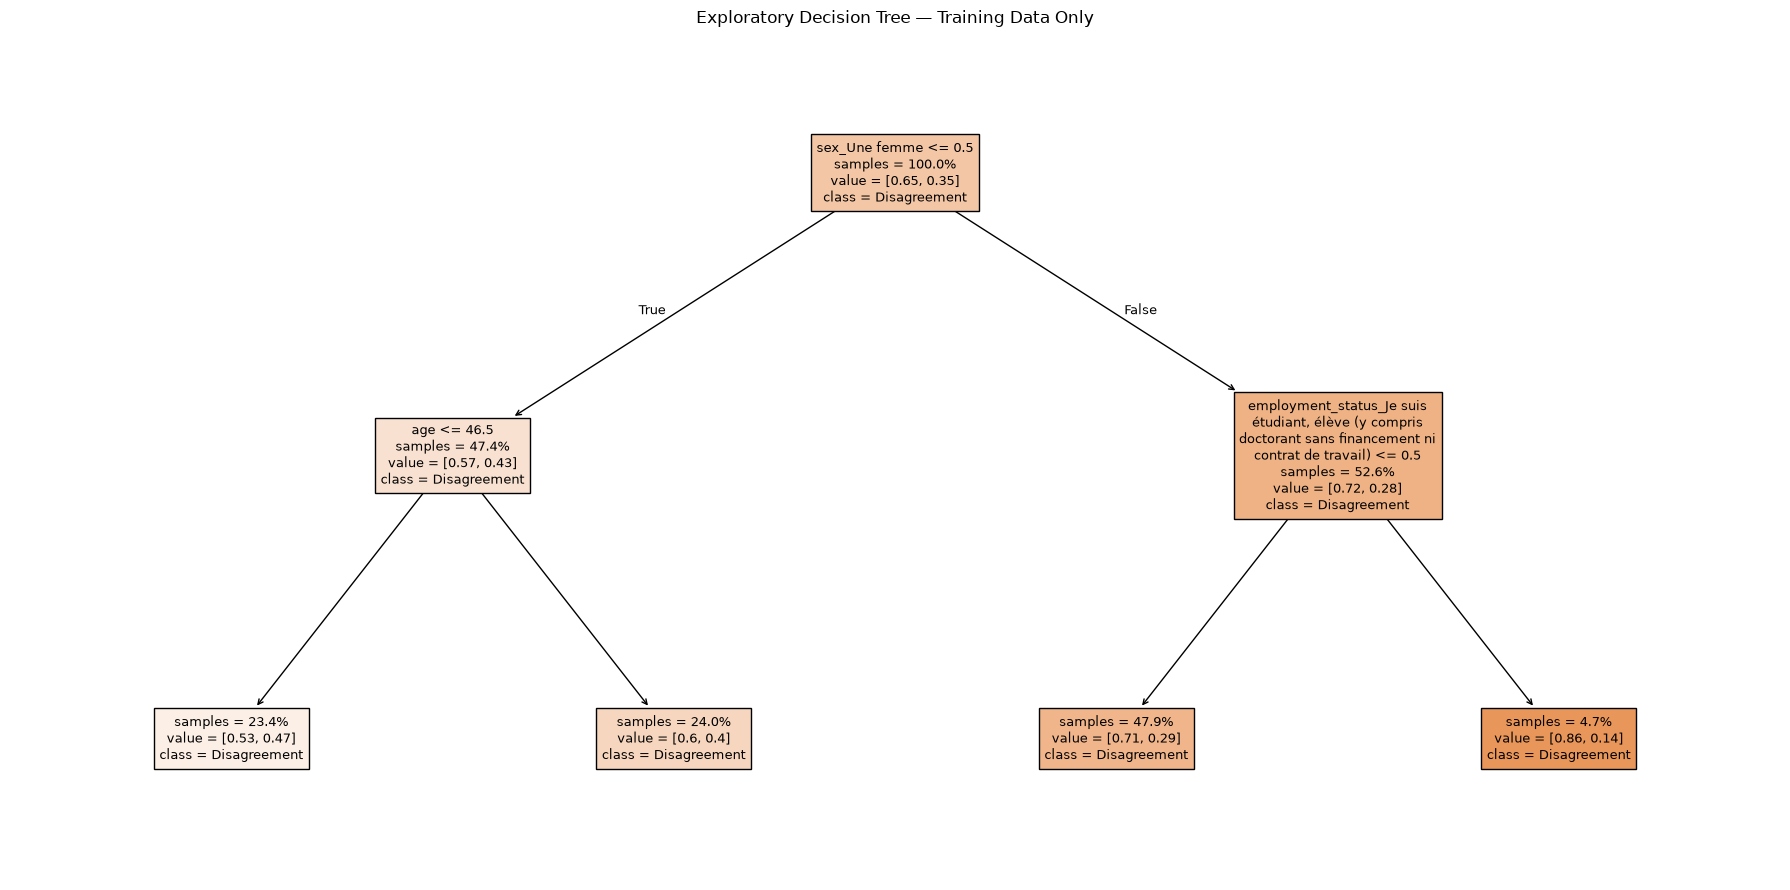

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from textwrap import fill

# Keep age in years so the tree is easier to read
tree_preprocessor = clone(preprocessor)
tree_preprocessor.set_params(numeric="passthrough")

X_tree_train = tree_preprocessor.fit_transform(X_train)

# Limit complexity for an exploratory illustration
illustration_tree = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=100,
    random_state=SEED
)

illustration_tree.fit(
    X_tree_train,
    y_train,
    sample_weight=weights_train
)

# Shorten and wrap labels for display
tree_feature_names = [
    fill(name.split("__", 1)[-1], width=30)
    for name in tree_preprocessor.get_feature_names_out()
]

fig, ax = plt.subplots(figsize=(18, 9))

plot_tree(
    illustration_tree,
    feature_names=tree_feature_names,
    class_names=["Disagreement", "Agreement"],
    filled=True,
    impurity=False,
    proportion=True,
    precision=2,
    fontsize=9,
    ax=ax
)

ax.set_title("Exploratory Decision Tree — Training Data Only")
plt.tight_layout()
plt.show()

### Exploratory tree interpretation

This shallow tree illustrates patterns in the training set only.

Weighted agreement shares differ across its branches, from approximately
14% to 47%. However, disagreement remains the majority response in every leaf.

The age threshold was selected from the training data. It is not an
established demographic boundary.

These exploratory patterns do not establish causality or justify
individual profiling. The tree was not used to replace the selected model.

In [16]:
from pathlib import Path
import joblib

# Save the fitted preprocessing and classifier together
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

model_path = model_folder / "hce_agreement_classifier.joblib"
joblib.dump(selected_model, model_path)

print("Saved:", model_path)

Saved: models\hce_agreement_classifier.joblib


In [17]:
# Save the final survey-weighted test metrics
test_metrics = pd.DataFrame([{
    "model": "SGD logistic regression",
    "alpha": 0.01,
    "class_weight": "balanced",
    "test_respondents": len(y_test),
    "accuracy": accuracy_score(
        y_test, test_predictions,
        sample_weight=weights_test
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_predictions,
        sample_weight=weights_test
    ),
    "roc_auc": roc_auc_score(
        y_test, test_probabilities,
        sample_weight=weights_test
    )
}])

test_metrics.to_csv(
    "data/processed/hce_model_test_metrics.csv",
    index=False
)

print("Saved: data/processed/hce_model_test_metrics.csv")

Saved: data/processed/hce_model_test_metrics.csv


## Conclusion

This study tested whether five sociodemographic characteristics could
predict agreement with the statement:
“Feminism threatens men's place and role in society.”

The analysis retained 2,779 expressed responses.
Non-response and “Don't know” answers were excluded.

A majority-class baseline, SGD logistic regression and Random Forest
were compared using cross-validation on the training set.
Preprocessing was fitted separately within each training fold.
Survey weights were used during training and evaluation.

The selected logistic model used alpha=0.01 and balanced class weights.
On the held-out test set, it achieved:
- Balanced accuracy: 0.579.
- ROC AUC: 0.570.
- Precision for agreement: 0.418.
- Recall for agreement: 0.636.

These results indicate weak predictive ability, despite performance
being close to cross-validation results. The model does not support
individual profiling or operational targeting.

The analysis contributes to CIDFF's reflection on prevention themes,
but does not establish which audiences need an intervention or whether
an intervention would be effective.

The findings concern one declared attitude in a national survey.
They do not establish causality, identify masculinist individuals,
or directly describe CIDFF users.

The exploratory tree was added after final model evaluation.
It illustrates training-set patterns only and did not change model selection.

The fitted pipeline and final test metrics were exported for reproducibility
and presentation in Streamlit.

In [22]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1
